In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, mannwhitneyu, spearmanr

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())


Rows: 891
Columns: 15


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [2]:

df.info()

display(df.describe(include="all"))

print("Missing values:")
print(df.isnull().sum())

print("Missing percentages:")
print((df.isnull().mean() * 100).round(2))

print("Duplicate rows:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64
Missing percentages:
survived        0.00
pclass          0.00
sex             0.00
age            19.87
sibsp           0.00
parch           0.00
fare            0.00
embarked        0.22
class           0.00
who             0.00
adult_male      0.00
deck           77.22
embark_town     0.22
alive           0.00
alone           0.00
dtype: float64
Duplicate rows: 107


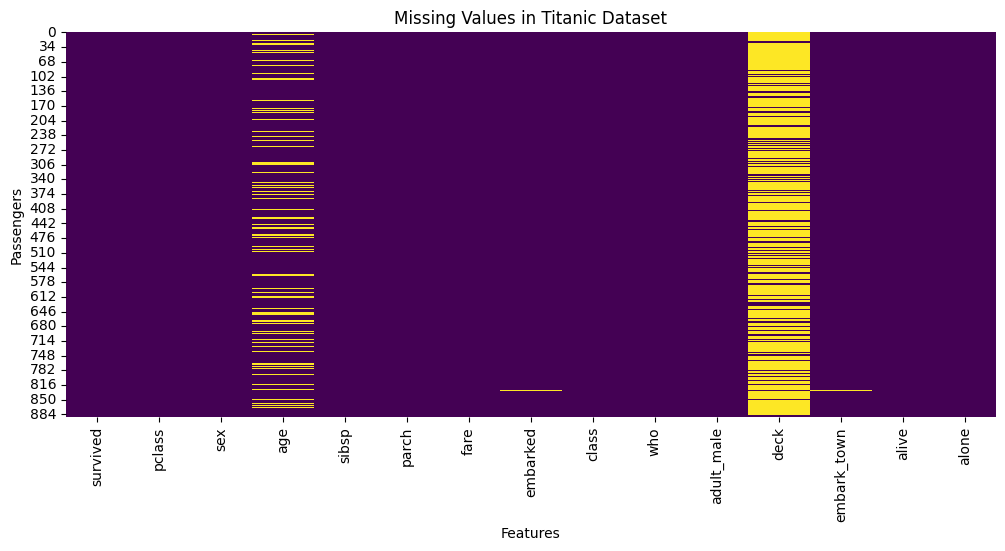

In [3]:

plt.figure(figsize=(12, 5))

sns.heatmap(df.isnull(), cbar=False, cmap="viridis")

plt.title("Missing Values in Titanic Dataset")
plt.xlabel("Features")
plt.ylabel("Passengers")
plt.show()


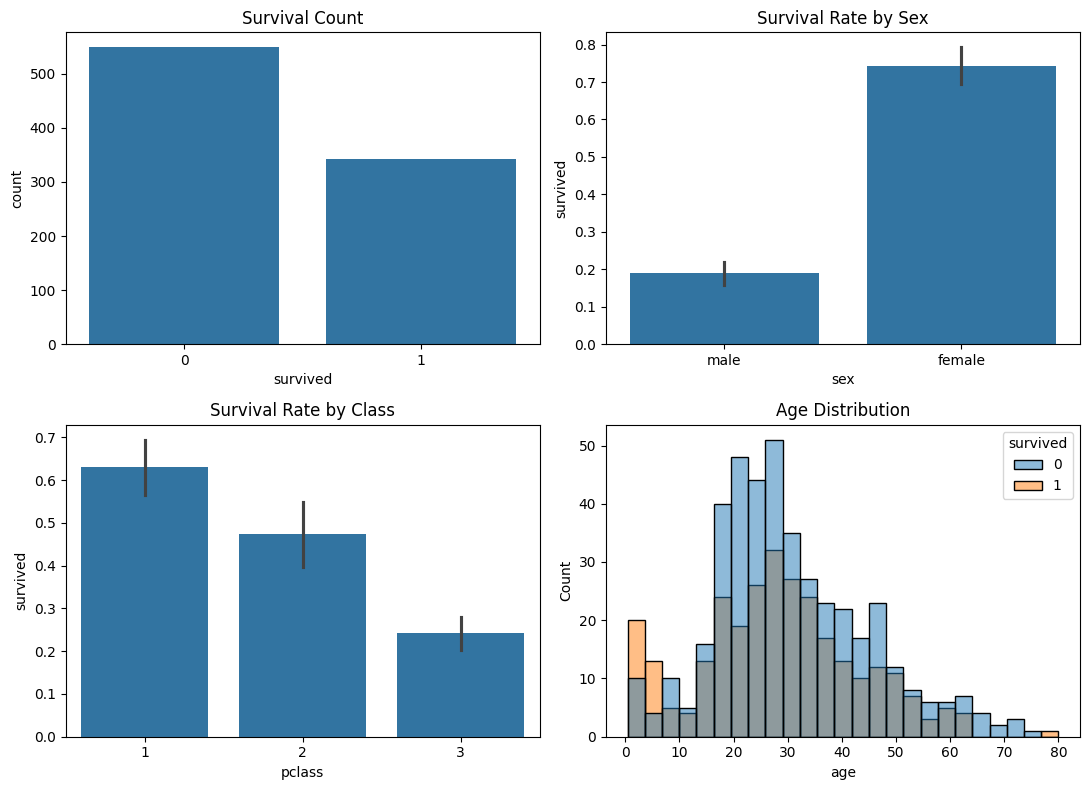

In [4]:

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

sns.countplot(data=df, x="survived", ax=axes[0, 0])
axes[0, 0].set_title("Survival Count")

sns.barplot(data=df, x="sex", y="survived", ax=axes[0, 1])
axes[0, 1].set_title("Survival Rate by Sex")

sns.barplot(data=df, x="pclass", y="survived", ax=axes[1, 0])
axes[1, 0].set_title("Survival Rate by Class")

sns.histplot(data=df, x="age", hue="survived", bins=25, ax=axes[1, 1])
axes[1, 1].set_title("Age Distribution")

plt.tight_layout()
plt.show()


age outliers: 11
fare outliers: 116
sibsp outliers: 46
parch outliers: 213


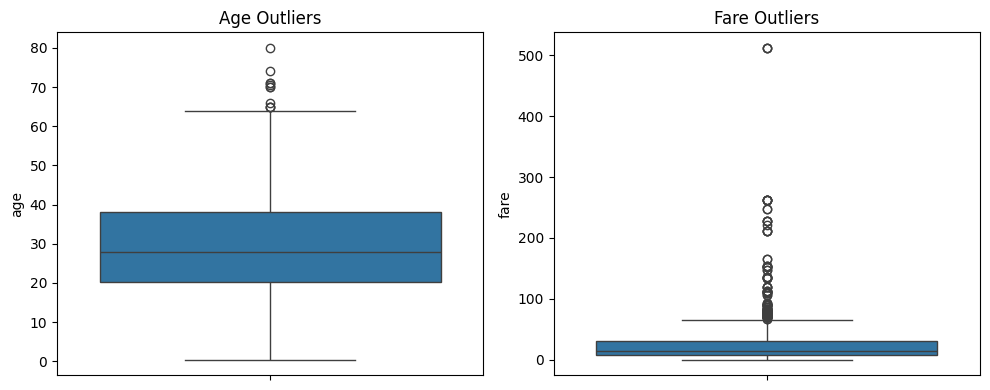

In [5]:

columns = ["age", "fare", "sibsp", "parch"]

for col in columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(col, "outliers:", count)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(y=df["age"], ax=axes[0])
axes[0].set_title("Age Outliers")

sns.boxplot(y=df["fare"], ax=axes[1])
axes[1].set_title("Fare Outliers")

plt.tight_layout()
plt.show()


In [6]:

table1 = pd.crosstab(df["sex"], df["survived"])

chi2, p1, dof, expected = chi2_contingency(table1)

print("Hypothesis 1: Sex and Survival")
print("P-value:", p1)

print("\nSurvival rates:")
print(df.groupby("sex")["survived"].mean().round(3))

if p1 < 0.05:
    print("Reject H0: Significant association")
else:
    print("Fail to reject H0")


Hypothesis 1: Sex and Survival
P-value: 1.1973570627755645e-58

Survival rates:
sex
female    0.742
male      0.189
Name: survived, dtype: float64
Reject H0: Significant association


In [7]:

table2 = pd.crosstab(df["pclass"], df["survived"])

chi2, p2, dof, expected = chi2_contingency(table2)

print("Hypothesis 2: Class and Survival")
print("P-value:", p2)

print("\nSurvival rates:")
print(df.groupby("pclass")["survived"].mean().round(3))

if p2 < 0.05:
    print("Reject H0: Significant association")
else:
    print("Fail to reject H0")


Hypothesis 2: Class and Survival
P-value: 4.549251711298793e-23

Survival rates:
pclass
1    0.630
2    0.473
3    0.242
Name: survived, dtype: float64
Reject H0: Significant association


In [8]:

ages_survived = df[df["survived"] == 1]["age"].dropna()
ages_died = df[df["survived"] == 0]["age"].dropna()

stat, p3 = mannwhitneyu(
    ages_survived,
    ages_died,
    alternative="two-sided"
)

print("Hypothesis 3: Age and Survival")
print("P-value:", p3)

print("Survivor median age:", ages_survived.median())
print("Non-survivor median age:", ages_died.median())

if p3 < 0.05:
    print("Reject H0: Significant difference")
else:
    print("Fail to reject H0")


Hypothesis 3: Age and Survival
P-value: 0.16049252477737763
Survivor median age: 28.0
Non-survivor median age: 28.0
Fail to reject H0


In [9]:

print("Alive vs Survived:")
print(pd.crosstab(df["alive"], df["survived"]))

print("\nClass vs Pclass:")
print(pd.crosstab(df["class"], df["pclass"]))

print("\nEmbarked vs Embark Town:")
print(pd.crosstab(df["embarked"], df["embark_town"]))

print("\nAlone vs Family Members:")
family_alone = (df["sibsp"] + df["parch"] == 0)
print(pd.crosstab(df["alone"], family_alone))


Alive vs Survived:
survived    0    1
alive             
no        549    0
yes         0  342

Class vs Pclass:
pclass    1    2    3
class                
First   216    0    0
Second    0  184    0
Third     0    0  491

Embarked vs Embark Town:
embark_town  Cherbourg  Queenstown  Southampton
embarked                                       
C                  168           0            0
Q                    0          77            0
S                    0           0          644

Alone vs Family Members:
col_0  False  True 
alone              
False    354      0
True       0    537


In [10]:

features = ["sex", "pclass", "embarked", "alone"]

for col in features:
    print("\nFeature:", col)
    print(df.groupby(col)["survived"].agg(["mean", "count"]).round(3))



Feature: sex
         mean  count
sex                 
female  0.742    314
male    0.189    577

Feature: pclass
         mean  count
pclass              
1       0.630    216
2       0.473    184
3       0.242    491

Feature: embarked
           mean  count
embarked              
C         0.554    168
Q         0.390     77
S         0.337    644

Feature: alone
        mean  count
alone              
False  0.506    354
True   0.304    537


,Feature,Correlation,P-value
0,age,-0.052565,1.605886e-01
1,fare,0.323736,3.471228e-23
2,sibsp,0.088879,7.941431e-03
3,parch,0.138266,3.453591e-05


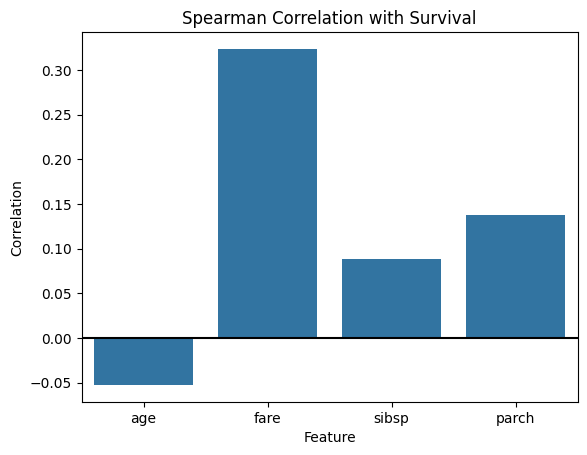

In [11]:

numeric_features = ["age", "fare", "sibsp", "parch"]

results = []

for col in numeric_features:
    data = df[[col, "survived"]].dropna()
    r, p = spearmanr(data[col], data["survived"])

    results.append([col, r, p])

correlations = pd.DataFrame(
    results,
    columns=["Feature", "Correlation", "P-value"]
)

display(correlations)

sns.barplot(data=correlations, x="Feature", y="Correlation")
plt.title("Spearman Correlation with Survival")
plt.axhline(0, color="black")
plt.show()


In [12]:

hypotheses = pd.DataFrame({
    "Hypothesis": [
        "Sex and Survival",
        "Class and Survival",
        "Age and Survival"
    ],
    "Test": [
        "Chi-square",
        "Chi-square",
        "Mann-Whitney U"
    ],
    "P-value": [p1, p2, p3]
})

hypotheses["Decision"] = np.where(
    hypotheses["P-value"] < 0.05,
    "Reject H0",
    "Fail to reject H0"
)

display(hypotheses)


,Hypothesis,Test,P-value,Decision
0,Sex and Survival,Chi-square,1.197357e-58,Reject H0
1,Class and Survival,Chi-square,4.549252e-23,Reject H0
2,Age and Survival,Mann-Whitney U,1.604925e-01,Fail to reject H0


In [13]:

from statsmodels.stats.multitest import multipletests

reject, adjusted_p, _, _ = multipletests(
    [p1, p2, p3],
    alpha=0.05,
    method="holm"
)

hypotheses["Adjusted P-value"] = adjusted_p
hypotheses["Holm Decision"] = np.where(
    reject,
    "Reject H0",
    "Fail to reject H0"
)

display(hypotheses)


,Hypothesis,Test,P-value,Decision,Adjusted P-value,Holm Decision
0,Sex and Survival,Chi-square,1.197357e-58,Reject H0,3.592071e-58,Reject H0
1,Class and Survival,Chi-square,4.549252e-23,Reject H0,9.098503e-23,Reject H0
2,Age and Survival,Mann-Whitney U,1.604925e-01,Fail to reject H0,1.604925e-01,Fail to reject H0


 # Exploratory Data Analysis of the Titanic Dataset

## 1. Introduction

The objective of this assignment was to perform Exploratory Data Analysis (EDA) on a dataset containing data quality problems, formulate and statistically test three hypotheses, investigate potential data leakage, and identify features likely to be important for machine learning.

The Titanic dataset contains 891 passenger records and 15 features. The target variable is `survived`, where 1 represents survival and 0 represents non-survival.

## 2. Data Quality Analysis

The initial analysis identified missing values in several columns, including `age`, `deck`, and `embarked`.

The `deck` feature contains a particularly high proportion of missing data. Missing values would need to be handled carefully before building a predictive model.

I also investigated duplicate rows and potential outliers using the Interquartile Range (IQR) method.

Unusual values were identified in numerical features such as `fare`. However, extreme values do not necessarily represent errors, so they should not be removed without further investigation.

## 3. Statistical Hypothesis Testing

Three hypotheses were tested at a significance level of 0.05.

**Hypothesis 1: Sex and Survival**

A Chi-square test of independence was used to investigate the relationship between sex and survival.

P-value: [Insert Step 6 result]

Conclusion: [State whether the null hypothesis was rejected and compare survival rates.]

**Hypothesis 2: Passenger Class and Survival**

A Chi-square test was used to determine whether passenger class was associated with survival.

P-value: [Insert Step 7 result]

Conclusion: [State whether the null hypothesis was rejected and describe the class differences.]

**Hypothesis 3: Age and Survival**

A Mann–Whitney U test was used to compare the age distributions of survivors and non-survivors.

P-value: [Insert Step 8 result]

Conclusion: [State whether the null hypothesis was rejected, and compare the median ages.]

Holm-adjusted p-values were also calculated to account for multiple hypothesis tests.

## 4. Potential Data Leakage

The analysis identified direct target leakage in the `alive` feature because it contains the same outcome information as `survived`.

Therefore, this feature must be excluded from any predictive model.

Other features, such as `class`, `embark_town`, and `alone`, contain information already represented by other variables. These are redundant or derived features rather than direct target leakage.

Preprocessing steps should also be fitted only on training data to prevent information from the evaluation dataset influencing the model.

## 5. Expected Feature Importance

Based on the survival-rate comparisons and statistical analysis, sex and passenger class are expected to be strong predictors of survival.

Fare may also be useful because it provides additional information about passengers' travel circumstances.

Age is another candidate, although its predictive usefulness requires further evaluation, particularly because some age values are missing.

These are hypotheses about feature importance based on EDA, not confirmed results from a trained model.

## 6. Conclusion

The EDA process identified missing values, potential outliers, redundant variables, and target leakage.

Statistical hypothesis testing provided evidence about relationships between passenger characteristics and survival.

The findings suggest that sex, passenger class, fare, and potentially age are useful candidates for a future predictive model.

Overall, this assignment demonstrates how exploratory analysis can guide data preparation, hypothesis testing, and feature selection before machine learning.